# LAB08 + LAB09 · Sistemas recomendadores
Victor Perez · INF-8239 · UASD

Ejecución real sobre MovieLens. No se incorporan filas del dataset al notebook. Los rankings son productos del análisis. Consulte las tarjetas y el informe para interpretar los límites.

In [1]:
from pathlib import Path
import os, sys, subprocess, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
os.chdir(ROOT)
print('Python:', sys.version.split()[0])
if not (ROOT/'data/raw/ml-latest-small/ratings.csv').exists():
    subprocess.run([sys.executable,'scripts/download_data.py'],check=True)

Python: 3.12.14


## Procedencia y auditoría
Se validan claves, nulos, columnas, rango, incrementos de ratings y timestamps. Las tarjetas describen la licencia y el sesgo de selección.

In [2]:
from inf8239_u03.data import load_movielens
from inf8239_u03.config import MOVIELENS_DIR
ratings,movies = load_movielens(MOVIELENS_DIR)
print(json.dumps(json.loads((ROOT/'reports/download_manifest.json').read_text()),indent=2))
print({'usuarios':int(ratings.userId.nunique()),'peliculas':len(movies),'ratings':len(ratings)})

{
  "url": "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip",
  "downloaded_utc": "2026-10-23T10:46:44.692845+00:00",
  "sha256_zip": "696d65a3dfceac7c45750ad32df2c259311949efec81f0f144fdfb91ebc9e436",
  "source": "GroupLens Research, University of Minnesota",
  "license_url": "https://files.grouplens.org/datasets/movielens/ml-latest-small-README.html"
}
{'usuarios': 610, 'peliculas': 9742, 'ratings': 100836}


## Experimento completo
Mismo corte por usuario; modelos 8 factores/4 épocas y 20/12; semillas 17, 42 y 83; alpha 0.25 y 0.75. Se puntúa todo el catálogo sin películas vistas. El corte por usuario no impide fuga temporal entre usuarios; hay empates de timestamp resueltos por movieId. La selección es exploratoria sobre esta prueba, sin test independiente posterior.

In [3]:
run = subprocess.run([sys.executable,'scripts/run_experiments.py'],capture_output=True,text=True,encoding='utf-8')
(ROOT/'reports/experiment_log.txt').write_text(run.stdout+run.stderr,encoding='utf-8')
assert run.returncode == 0, run.stderr
print('Experimentos completos. Registro en reports/experiment_log.txt')
import pandas as pd
summary = pd.read_csv(ROOT/'reports/pareto.csv')
display(summary.round(6))

Experimentos completos. Registro en reports/experiment_log.txt


,method,factors,epochs,alpha,runs,hit_rate_at_10,hr_std,precision_at_10,positive_hit_rate_at_10,coverage,rmse,total_seconds,model_bytes,pareto
0,collaborative,8,4,1.00,3,0.000546,0.000946,0.000055,0.000000,0.131116,1.115918,4.421556,1094137.0,True
1,collaborative,20,12,1.00,3,0.033880,0.009606,0.003388,0.049587,0.073394,1.027715,10.179497,2084002.0,True
2,content,0,0,0.00,1,0.001639,NaN,0.000164,0.002755,0.079450,NaN,0.787761,1080087.0,True
3,hybrid,8,4,0.25,3,0.002186,0.001893,0.000219,0.002755,0.176555,1.115918,4.388571,2049212.0,True
4,hybrid,8,4,0.75,3,0.002186,0.001893,0.000219,0.000918,0.171423,1.115918,4.402897,2049212.0,False
5,hybrid,20,12,0.25,3,0.014208,0.003413,0.001421,0.010101,0.131150,1.027715,10.201869,3039068.0,True
6,hybrid,20,12,0.75,3,0.032787,0.002839,0.003279,0.044995,0.095566,1.027715,10.237450,3039068.0,True
7,popularity,0,0,0.00,1,0.031148,NaN,0.003115,0.046832,0.006877,1.116857,0.714661,156133.0,True


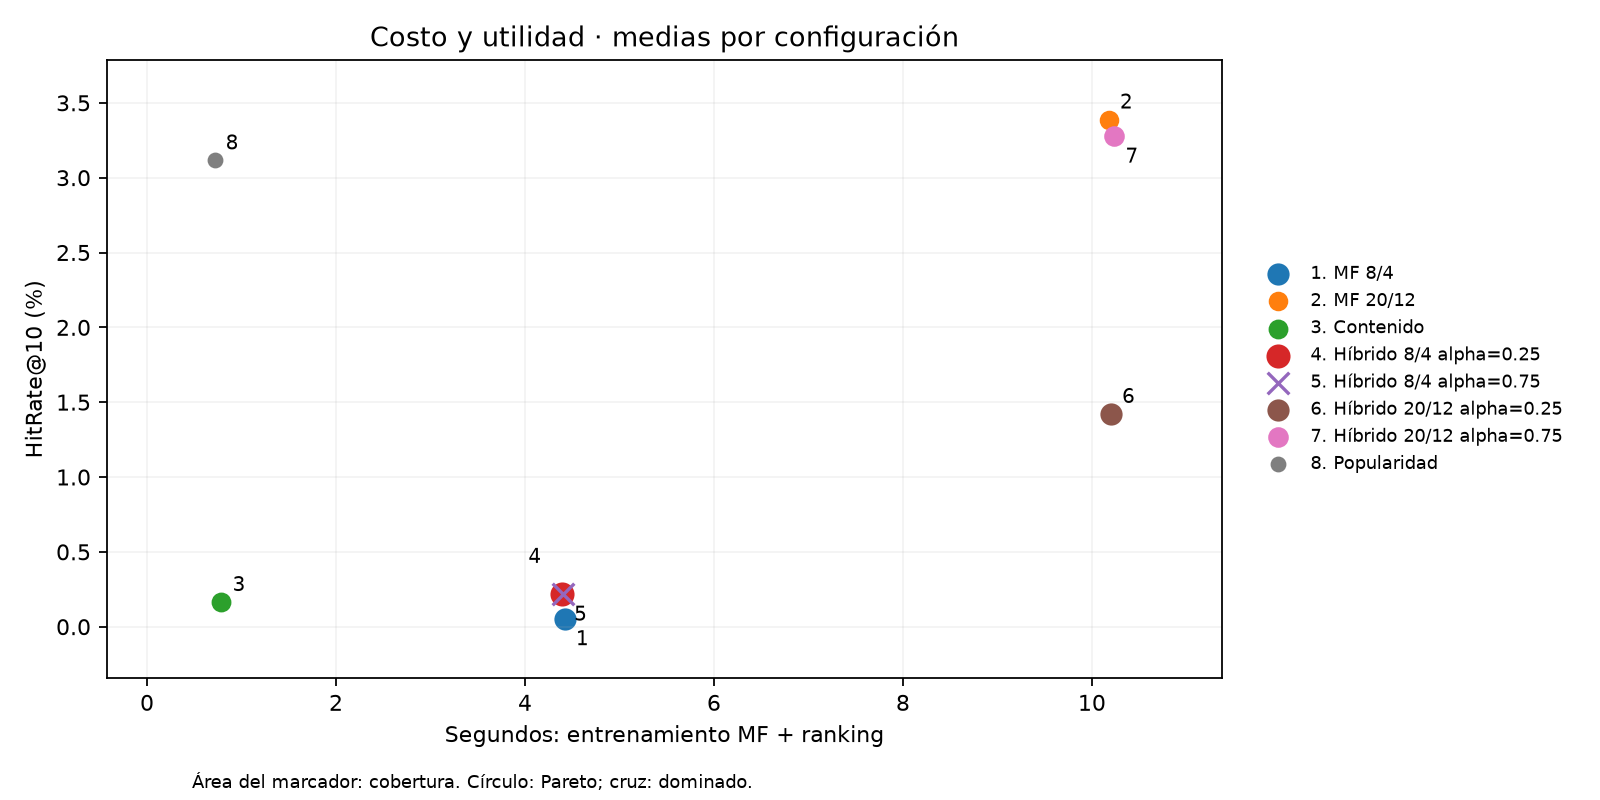

{
  "users": 610,
  "movies": 9742,
  "rated_movies": 9724,
  "ratings": 100836,
  "density": 0.016968273253211548,
  "min_utc": "1996-03-29 18:36:55+00:00",
  "max_utc": "2018-09-24 14:27:30+00:00",
  "rating_distribution": {
    "0.5": 1370,
    "1.0": 2811,
    "1.5": 1791,
    "2.0": 7551,
    "2.5": 5550,
    "3.0": 20047,
    "3.5": 13136,
    "4.0": 26818,
    "4.5": 8551,
    "5.0": 13211
  },
  "train_rows": 100226,
  "test_rows": 610,
  "unseen_test_items": 23,
  "timestamp_ties_at_boundary": 94,
  "file_sha256": {
    "links.csv": "97ad18e4e56a09363c65676b6cb3482ce3e2cea2372a24620c1599c843325f31",
    "movies.csv": "5a5f32dd9bb3797b8e728a1b98958789d2b13f294a69fdfbc5727f8a9611aa07",
    "ratings.csv": "aa289ca83157595d0df6aea1be6a4ded676ddc4385472e8313a8ed9805352646",
    "tags.csv": "92a9f8bb7916dceef6151209845788c3643f794dfa79d1feaec7121b5960399d"
  },
  "run_utc": "2026-10-23T10:48:18.870549+00:00",
  "python": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0"
}


In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'reports/pareto.png')))
print(json.dumps(json.loads((ROOT/'reports/audit.json').read_text()),indent=2))

## Popularidad y tres consultas por contenido
El Top-10 de LAB08 es descriptivo sobre todos los ratings; la evaluación utiliza exclusivamente entrenamiento. Los empates aparecen al compartir el mismo vector TF-IDF de géneros. Las dimensiones latentes de MF no tienen nombres semánticos garantizados.

In [5]:
display(pd.read_csv(ROOT/'reports/popular_top10.csv'))
content = pd.read_csv(ROOT/'reports/content_recommendations.csv')
for query, table in content.groupby('query',sort=False):
    print(query)
    assert query not in set(table.title)
    display(table.drop(columns='query'))

,movieId,mean,count,weighted_score,title,genres
0,318,4.429022,317,4.395194,"Shawshank Redemption, The (1994)",Crime|Drama
1,858,4.289062,192,4.242739,"Godfather, The (1972)",Crime|Drama
2,2959,4.272936,218,4.232690,Fight Club (1999),Action|Crime|Drama|Thriller
3,260,4.231076,251,4.197790,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
4,50,4.237745,204,4.196846,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
5,1221,4.259690,129,4.195168,"Godfather: Part II, The (1974)",Crime|Drama
6,527,4.225000,220,4.187581,Schindler's List (1993),Drama|War
7,1213,4.250000,126,4.184918,Goodfellas (1990),Crime|Drama
8,750,4.268041,97,4.183658,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War
9,58559,4.238255,149,4.183346,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX


Toy Story (1995)


,movieId,title,genres,content_score
0,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,91355,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0
5,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
6,45074,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
7,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
8,136016,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,1.0
9,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0


Shawshank Redemption, The (1994)


,movieId,title,genres,content_score
10,8656,"Short Film About Killing, A (Krótki film o zab...",Crime|Drama,1.0
11,63768,Tattooed Life (Irezumi ichidai) (1965),Crime|Drama,1.0
12,62250,Gomorrah (Gomorra) (2008),Crime|Drama,1.0
13,161127,The Infiltrator (2016),Crime|Drama,1.0
14,60753,Felon (2008),Crime|Drama,1.0
15,1466,Donnie Brasco (1997),Crime|Drama,1.0
16,45210,United 93 (2006),Crime|Drama,1.0
17,43912,Freedomland (2006),Crime|Drama,1.0
18,44301,Lights in the Dusk (Laitakaupungin valot) (2006),Crime|Drama,1.0
19,1227,Once Upon a Time in America (1984),Crime|Drama,1.0


Exorcist, The (1973)


,movieId,title,genres,content_score
20,27434,Darkness (2002),Horror|Mystery,1.0
21,3476,Jacob's Ladder (1990),Horror|Mystery,1.0
22,2898,"Dark Half, The (1993)",Horror|Mystery,1.0
23,1130,"Howling, The (1980)",Horror|Mystery,1.0
24,114707,Horns (2014),Horror|Mystery,1.0
25,4143,Valentine (2001),Horror|Mystery,1.0
26,775,Spirits of the Dead (1968),Horror|Mystery,1.0
27,4195,"Abominable Dr. Phibes, The (1971)",Horror|Mystery,1.0
28,1335,Blood Beach (1981),Horror|Mystery,1.0
29,6967,Dead of Night (1945),Horror|Mystery,1.0


## Tres perfiles
El historial pequeño es el menor dentro de MovieLens, no un usuario verdaderamente nuevo. El perfil nuevo (-1) es sintético y usa popularidad no personalizada. Las listas con varias semillas permiten inspeccionar estabilidad.

In [6]:
profiles = pd.read_csv(ROOT/'reports/profile_recommendations.csv')
example = profiles[(profiles.method=='hybrid') & (profiles.factors==20) & (profiles.seed==42) & (profiles.alpha==0.75)]
for profile,table in example.groupby('profile',sort=False):
    print(profile, 'historial:',table.history_size.iloc[0])
    display(table[['rank','title']])

amplio historial: 2697


,rank,title
480,1,12 Angry Men (1957)
481,2,Life Is Beautiful (La Vita è bella) (1997)
482,3,Intouchables (2011)
483,4,"Philadelphia Story, The (1940)"
484,5,Modern Times (1936)
485,6,My Fair Lady (1964)
486,7,Annie Hall (1977)
487,8,Manhattan (1979)
488,9,"Lives of Others, The (Das leben der Anderen) (..."
489,10,Man Bites Dog (C'est arrivé près de chez vous)...


pequeno historial: 19


,rank,title
490,1,Annie Hall (1977)
491,2,"Godfather, The (1972)"
492,3,Punch-Drunk Love (2002)
493,4,Slumdog Millionaire (2008)
494,5,Rocky (1976)
495,6,Match Point (2005)
496,7,About a Boy (2002)
497,8,Apocalypse Now (1979)
498,9,Notting Hill (1999)
499,10,"Wolf of Wall Street, The (2013)"


nuevo historial: 0


,rank,title
500,1,"Shawshank Redemption, The (1994)"
501,2,"Godfather, The (1972)"
502,3,Fight Club (1999)
503,4,Star Wars: Episode IV - A New Hope (1977)
504,5,"Usual Suspects, The (1995)"
505,6,"Godfather: Part II, The (1974)"
506,7,"Princess Bride, The (1987)"
507,8,Goodfellas (1990)
508,9,Schindler's List (1993)
509,10,"Dark Knight, The (2008)"


## Verificación
Las pruebas incluyen exclusión de vistos, fallback, extremos del híbrido, corte temporal, errores de datos y dominancia de Pareto.

In [7]:
check = subprocess.run([sys.executable,'-m','pytest','-q','-p','no:cacheprovider'],capture_output=True,text=True)
print(check.stdout)
assert check.returncode == 0, check.stderr
(ROOT/'reports/tests.txt').write_text(check.stdout,encoding='utf-8')

................                                                         [100%]
16 passed in 3.24s



99

## Conclusión y declaración de IA
La decisión se obtiene de las métricas ejecutadas y se documenta en `docs/CONCLUSION.md` y el PDF. Una mejora offline no prueba satisfacción; se necesita validación independiente, un corte global estricto y evaluación de diversidad. Codex ayudó a completar código, experimentos, pruebas y redacción; los prompts, correcciones y verificaciones figuran en `docs/AI_USAGE.md`. El estudiante debe revisar y poder explicar esta entrega.